In [7]:
from datetime import datetime
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.constants import c, k_B
from astropy.io import fits
from astropy.nddata import Cutout2D
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_area, proj_plane_pixel_scales
from matplotlib.colors import LogNorm
from matplotlib.patches import Circle

base_results_dir = Path("/Users/reiya/Desktop/imaging/results_fov3000")
target_dates = None  # 例：["2023-05-21", "2023-06-01"]。Noneは全観測日
crop_size_uas = 800.0
core_radius_uas = 75.0
core_xy = None  # NoneならMean画像の最大輝度画素。手動なら (x, y)

# "auto", "jy_per_pixel", "jy_per_beam", "jy_per_sr"
unit_mode = "auto"
beam_major_uas = None  # Jy/beamでヘッダーにBMAJ/BMINがない場合
beam_minor_uas = None
OBS_FREQUENCY_GHZ = 43.0  # NoneならFITSヘッダーから取得
DISPLAY_LOG = True

ERROR_MODE = "std_fits"  # または "posterior_samples"
STD_SUFFIX = "_simg.fits"  # ファイル名が *_std.fits なら "_std.fits"

In [9]:
def read_image(path):
    with fits.open(path) as hdul:
        for hdu in hdul:
            if hdu.data is not None and hdu.data.ndim >= 2:
                data = np.array(hdu.data, dtype=float, copy=True).squeeze()
                header = hdu.header.copy()
                break
        else:
            raise ValueError(f"画像が見つかりません: {path}")

    if data.ndim != 2 or not np.isfinite(data).any():
        raise ValueError(f"有効な2次元画像が必要です: {path}, shape={data.shape}")
    return data, header


def get_image_wcs(header, path):
    if header.get("CTYPE2") == "DEC---SIN":
        header["CTYPE2"] = "DEC--SIN"
    wcs = WCS(header, naxis=2, relax=True, fix=True)
    if not wcs.has_celestial:
        raise ValueError(f"RA・DecのWCS情報がありません: {path}")
    return wcs.celestial


def get_frequency_hz(header):
    frequency_hz = None
    if OBS_FREQUENCY_GHZ is not None:
        frequency_hz = float(OBS_FREQUENCY_GHZ) * 1e9
    else:
        scales = {"hz": 1.0, "khz": 1e3, "mhz": 1e6, "ghz": 1e9}
        for axis in range(1, int(header.get("NAXIS", 2)) + 1):
            ctype = str(header.get(f"CTYPE{axis}", "")).strip().upper()
            value = header.get(f"CRVAL{axis}")
            if ctype.startswith("FREQ") and value is not None:
                unit = str(header.get(f"CUNIT{axis}", "Hz")).strip().lower()
                if unit not in scales:
                    raise ValueError(f"未対応の周波数単位: {unit}")
                frequency_hz = float(value) * scales[unit]
                break
        if frequency_hz is None:
            for key in ("FREQ", "OBSFREQ", "RF"):
                if header.get(key) is not None:
                    frequency_hz = float(header[key])
                    break

    if frequency_hz is None or not np.isfinite(frequency_hz) or frequency_hz <= 0:
        raise ValueError("観測周波数をOBS_FREQUENCY_GHZで指定してください。例：43.0")
    return frequency_hz


def normalized_bunit(header):
    return str(header.get("BUNIT", "")).lower().replace(" ", "")


def get_pixel_flux_factor(header, pixel_area_sr):
    """入力画素値に掛けると、その画素のフラックス [Jy] になる係数。"""
    bunit = normalized_bunit(header)
    if bunit.startswith(("mjy", "ujy", "µjy")):
        raise ValueError(f"入力はJy系の単位が必要です: BUNIT={header.get('BUNIT')!r}")

    mode = unit_mode
    if mode == "auto":
        if "beam" in bunit:
            mode = "jy_per_beam"
        elif "pix" in bunit or bunit in ("jy", "jansky"):
            mode = "jy_per_pixel"
            if bunit in ("jy", "jansky"):
                print("注意：BUNIT=JyをJy/pixelとして扱います")
        elif "/sr" in bunit or "sr-1" in bunit:
            mode = "jy_per_sr"

    if mode == "jy_per_pixel":
        return 1.0, mode
    if mode == "jy_per_sr":
        return pixel_area_sr, mode
    if mode != "jy_per_beam":
        raise ValueError(
            f"BUNIT={header.get('BUNIT')!r} を判定できません。unit_modeを確認してください"
        )

    if "BMAJ" in header and "BMIN" in header:
        major_deg = abs(float(header["BMAJ"]))
        minor_deg = abs(float(header["BMIN"]))
    elif beam_major_uas is not None and beam_minor_uas is not None:
        major_deg = (beam_major_uas * u.uas).to_value(u.deg)
        minor_deg = (beam_minor_uas * u.uas).to_value(u.deg)
    else:
        raise ValueError(
            "Jy/beam画像にはBMAJ・BMINか、手動で指定したビームサイズが必要です"
        )
    if not all(np.isfinite(size) and size > 0 for size in (major_deg, minor_deg)):
        raise ValueError("ビームサイズは正の有限値にしてください")

    beam_area_deg2 = np.pi * major_deg * minor_deg / (4.0 * np.log(2.0))
    beam_area_sr = (beam_area_deg2 * u.deg**2).to_value(u.sr)
    return pixel_area_sr / beam_area_sr, mode


def get_core_errors(fits_path, data, header, wcs, core_mask, to_K, to_Jy):
    stem = fits_path.stem.removesuffix("_mimg")
    if ERROR_MODE == "std_fits":
        error_path = fits_path.with_name(f"{stem}{STD_SUFFIX}")
    elif ERROR_MODE == "posterior_samples":
        error_path = fits_path.with_name(f"{stem}_posterior_samples.npy")
    else:
        raise ValueError(f"未対応のERROR_MODE: {ERROR_MODE}")

    if not error_path.is_file():
        print(f"誤差用ファイルが見つかりません: {error_path}")
        return np.nan, np.nan, np.nan

    if ERROR_MODE == "posterior_samples":
        samples = np.load(error_path, mmap_mode="r", allow_pickle=False)
        if samples.ndim != 3 or samples.shape[1:] != data.shape or len(samples) < 2:
            raise ValueError(
                f"(サンプル数, ny, nx) の配列で2枚以上が必要です: {error_path}"
            )

        core_draws = samples[:, core_mask].astype(float)
        if not np.isfinite(core_draws).all():
            raise ValueError(f"サンプルのコア領域に非有限値があります: {error_path}")

        return (
            core_draws.mean(axis=1).std(ddof=1) * to_K,
            core_draws.max(axis=1).std(ddof=1) * to_K,
            core_draws.sum(axis=1).std(ddof=1) * to_Jy,
        )

    std_image, std_header = read_image(error_path)
    if std_image.shape != data.shape:
        raise ValueError(f"Mean FITSとStd FITSの画像サイズが違います: {error_path}")

    mean_unit = normalized_bunit(header)
    std_unit = normalized_bunit(std_header)
    if mean_unit and std_unit and mean_unit != std_unit:
        raise ValueError(f"Mean FITSとStd FITSのBUNITが違います: {error_path}")

    std_wcs = get_image_wcs(std_header, error_path)
    core_y, core_x = np.nonzero(core_mask)
    separation = wcs.pixel_to_world(core_x, core_y).separation(
        std_wcs.pixel_to_world(core_x, core_y)
    )
    if not np.all(separation.to_value(u.uas) < 0.01):
        raise ValueError(f"Mean FITSとStd FITSのWCSが一致しません: {error_path}")

    sigma = std_image[core_mask]
    if not np.isfinite(sigma).all() or (sigma < 0).any():
        raise ValueError(f"コア領域のStdに無効値があります: {error_path}")

    peak_index = np.argmax(data[core_mask])
    return sigma.mean() * to_K, sigma[peak_index] * to_K, sigma.sum() * to_Jy

In [11]:
def analyze_epoch(obs_date, fits_path):
    data, header = read_image(fits_path)
    wcs = get_image_wcs(header, fits_path)
    scales = proj_plane_pixel_scales(wcs)
    unit_x = u.Unit(str(wcs.wcs.cunit[0]) or "deg")
    unit_y = u.Unit(str(wcs.wcs.cunit[1]) or "deg")
    pixel_size_x_uas = abs((scales[0] * unit_x).to_value(u.uas))
    pixel_size_y_uas = abs((scales[1] * unit_y).to_value(u.uas))
    pixel_area = abs(proj_plane_pixel_area(wcs)) * unit_x * unit_y
    pixel_area_sr = pixel_area.to_value(u.sr)
    if not np.isfinite(pixel_area_sr) or pixel_area_sr <= 0:
        raise ValueError(f"画素の立体角が無効です: {fits_path}")

    if core_xy is None:
        valid_data = np.where(np.isfinite(data), data, -np.inf)
        y_core, x_core = np.unravel_index(np.argmax(valid_data), data.shape)
    else:
        x_core, y_core = map(float, core_xy)

    yy, xx = np.indices(data.shape)
    radius_uas = np.hypot(
        (xx - x_core) * pixel_size_x_uas, (yy - y_core) * pixel_size_y_uas
    )
    core_mask = (radius_uas <= core_radius_uas) & np.isfinite(data)
    used_pixels = int(core_mask.sum())
    if used_pixels == 0:
        raise ValueError(f"コア領域内に有効な画素がありません: {fits_path}")

    frequency_hz = get_frequency_hz(header)
    to_Jy, selected_mode = get_pixel_flux_factor(header, pixel_area_sr)
    # 観測者系のRayleigh–Jeans輝度温度への換算
    to_K = c.value**2 * 1e-26 * to_Jy / (
        2.0 * k_B.value * frequency_hz**2 * pixel_area_sr
    )
    temperature_K = data * to_K
    core_mean_tb_K = float(temperature_K[core_mask].mean())
    core_peak_tb_K = float(temperature_K[core_mask].max())
    core_flux_jy = float(data[core_mask].sum() * to_Jy)

    mean_err, peak_err, flux_err = get_core_errors(
        fits_path, data, header, wcs, core_mask, to_K, to_Jy
    )

    if crop_size_uas < 2.0 * core_radius_uas:
        raise ValueError("crop_size_uasはcore_radius_uasの2倍以上にしてください")

    cutout = Cutout2D(
        temperature_K,
        position=(x_core, y_core),
        size=(crop_size_uas * u.uas, crop_size_uas * u.uas),
        wcs=wcs,
        mode="partial",
        fill_value=np.nan,
        copy=True,
    )
    x_cut, y_cut = cutout.to_cutout_position((x_core, y_core))
    ny, nx = cutout.data.shape
    extent = [
        (x_cut + 0.5) * pixel_size_x_uas,
        -(nx - x_cut - 0.5) * pixel_size_x_uas,
        -(y_cut + 0.5) * pixel_size_y_uas,
        (ny - y_cut - 0.5) * pixel_size_y_uas,
    ]

    output_dir = base_results_dir / f"Mrk501_{obs_date:%Y-%m-%d}" / "core_flux"
    output_dir.mkdir(parents=True, exist_ok=True)
    cutout_fits_path = output_dir / f"{fits_path.stem}_core_cutout_Tb.fits"
    png_path = output_dir / "core_brightness_temperature.png"

    cutout_header = cutout.wcs.to_header(relax=True)
    for key in ("BMAJ", "BMIN", "BPA", "OBJECT", "DATE-OBS"):
        if key in header:
            cutout_header[key] = header[key]
    cutout_header["BUNIT"] = "K"
    cutout_header["OBSFREQ"] = (frequency_hz, "Observing frequency in Hz")
    cutout_header.add_history("Observer-frame Rayleigh-Jeans brightness temperature.")
    cutout_header.add_history(f"Core cutout centered at pixel ({x_core:.3f}, {y_core:.3f})")
    fits.PrimaryHDU(
        data=cutout.data.astype(np.float32), header=cutout_header
    ).writeto(cutout_fits_path, overwrite=True)

    finite_data = cutout.data[np.isfinite(cutout.data)]
    if finite_data.size == 0:
        raise ValueError(f"切り出し画像に有効な画素がありません: {fits_path}")

    image_options = dict(origin="lower", extent=extent, cmap="inferno", aspect="equal")
    if DISPLAY_LOG:
        positive = finite_data[finite_data > 0]
        if positive.size == 0:
            raise ValueError(f"対数表示に使える正の画素がありません: {fits_path}")
        vmin, vmax = np.percentile(positive, 1), positive.max()
        if vmin >= vmax:
            vmin = vmax * 0.1
        image_options["norm"] = LogNorm(vmin=vmin, vmax=vmax)
    else:
        image_options.update(vmin=finite_data.min(), vmax=finite_data.max())

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cutout.data, **image_options)
    ax.add_patch(
        Circle(
            (0.0, 0.0), core_radius_uas,
            fill=False, edgecolor="cyan", linewidth=2,
        )
    )
    ax.axhline(0, color="white", alpha=0.3, linewidth=0.8)
    ax.axvline(0, color="white", alpha=0.3, linewidth=0.8)
    ax.set_xlabel(r"$\Delta$Right Ascension [$\mu$as]")
    ax.set_ylabel(r"$\Delta$Declination [$\mu$as]")
    ax.set_title(
        f"{obs_date:%Y-%m-%d}  Mean Tb = {core_mean_tb_K:.3g} K\n"
        f"Core flux = {core_flux_jy * 1000:.3f} mJy, radius = {core_radius_uas:g} μas"
    )
    fig.colorbar(im, ax=ax, label="Brightness temperature [K]")
    fig.tight_layout()
    fig.savefig(png_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"元画像: {fits_path} | {data.shape} | {selected_mode}")
    print(f"周波数: {frequency_hz / 1e9:g} GHz")
    print(f"コア中心: (x, y) = ({x_core:.3f}, {y_core:.3f}), 使用画素数: {used_pixels}")
    print(f"画素サイズ: {pixel_size_x_uas:.4f} × {pixel_size_y_uas:.4f} μas")
    print(f"コアの天球座標: {wcs.pixel_to_world(x_core, y_core)}")
    print(f"切り出しFITS: {cutout_fits_path}")
    print(f"確認画像: {png_path}")

    return {
        "date": obs_date,
        "mean_tb_K": core_mean_tb_K,
        "mean_tb_K_err": mean_err,
        "peak_tb_K": core_peak_tb_K,
        "peak_tb_K_err": peak_err,
        "flux_jy": core_flux_jy,
        "flux_jy_err": flux_err,
        "frequency_hz": float(frequency_hz),
        "used_pixels": used_pixels,
        "bunit": str(header.get("BUNIT", "")).strip(),
        "fits_path": str(fits_path),
    }

処理するエポック: 38 件

観測日: 2023-05-21


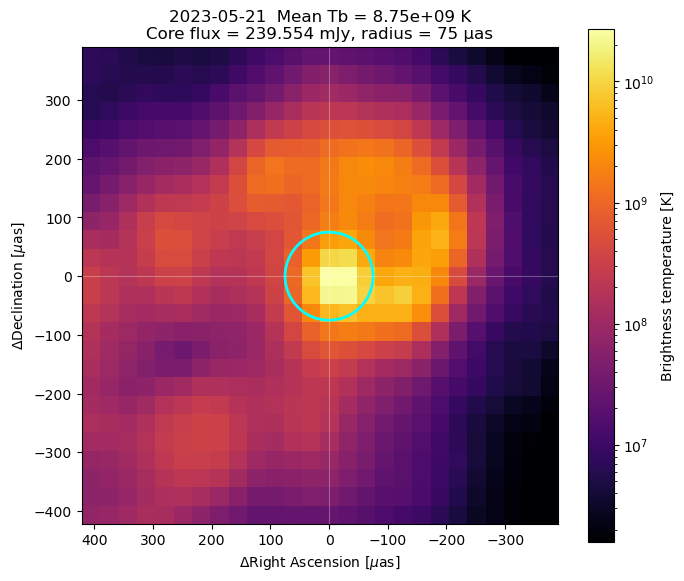

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/fits/1652+398Q.2023-05-21_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (50.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999998, 2.17013913e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/core_flux/1652+398Q.2023-05-21_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-05-21/core_flux/core_brightness_temperature.png

観測日: 2023-06-01


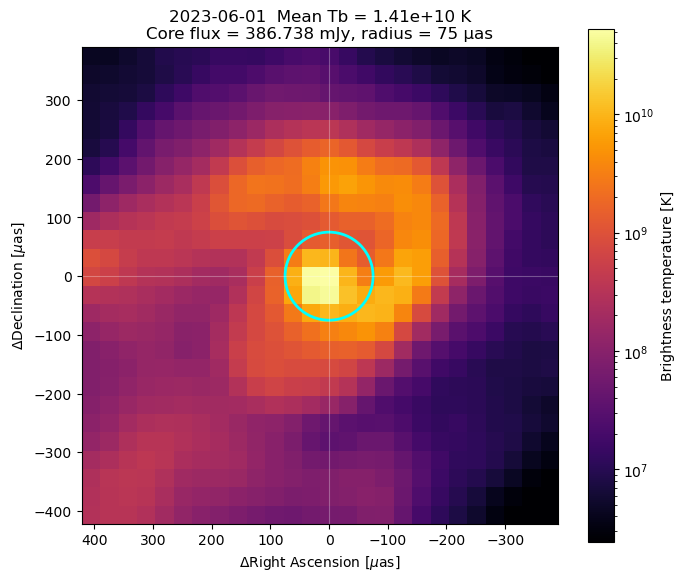

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-06-01/fits/1652+398Q.2023-06-01_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-06-01/core_flux/1652+398Q.2023-06-01_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-06-01/core_flux/core_brightness_temperature.png

観測日: 2023-07-01


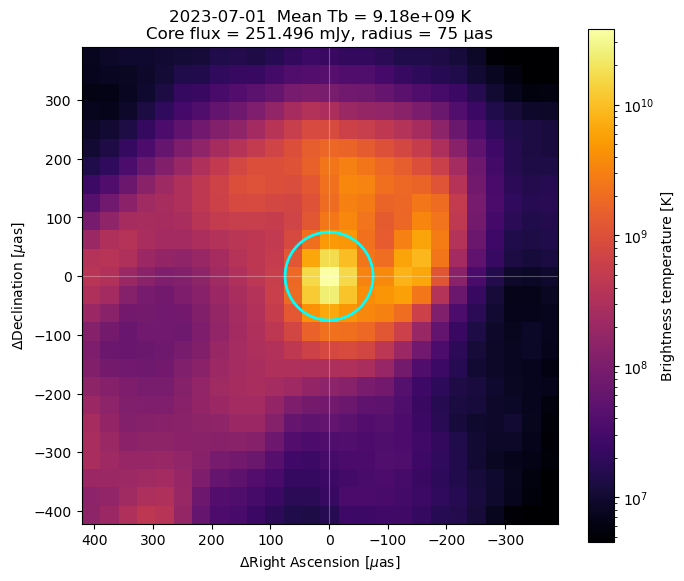

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-01/fits/1652+398Q.2023-07-01_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-01/core_flux/1652+398Q.2023-07-01_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-01/core_flux/core_brightness_temperature.png

観測日: 2023-07-15


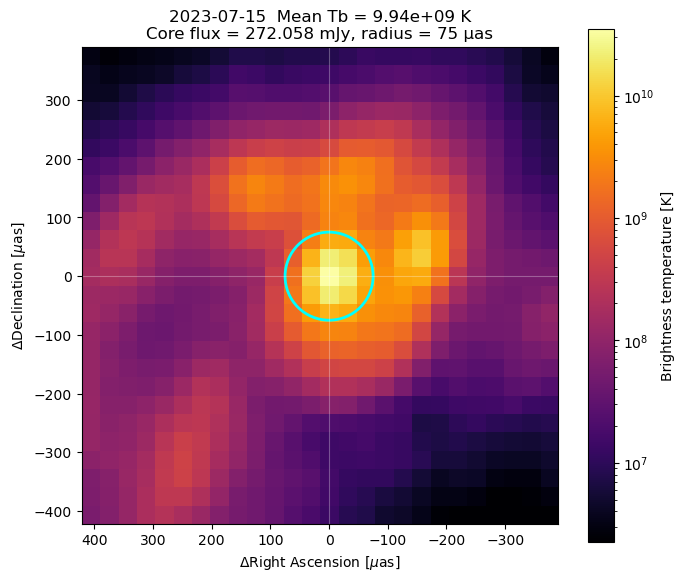

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-15/fits/1652+398Q.2023-07-15_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-15/core_flux/1652+398Q.2023-07-15_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-15/core_flux/core_brightness_temperature.png

観測日: 2023-07-24


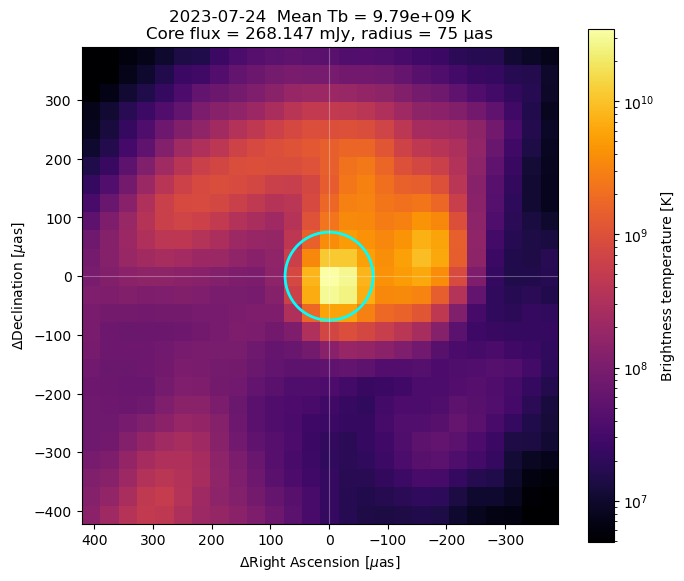

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-24/fits/1652+398Q.2023-07-24_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (49.000, 48.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999999, 4.34028197e-09)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-24/core_flux/1652+398Q.2023-07-24_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-07-24/core_flux/core_brightness_temperature.png

観測日: 2023-10-13


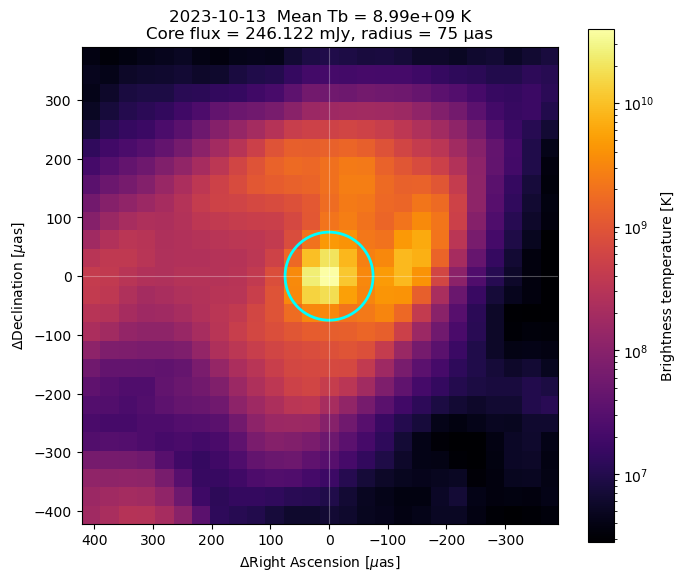

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-10-13/fits/1652+398Q.2023-10-13_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-10-13/core_flux/1652+398Q.2023-10-13_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-10-13/core_flux/core_brightness_temperature.png

観測日: 2023-10-21


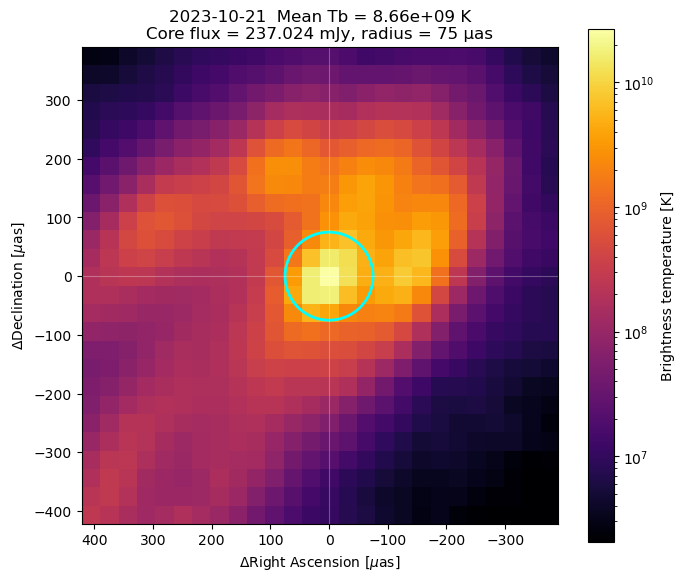

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-10-21/fits/1652+398Q.2023-10-21_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-10-21/core_flux/1652+398Q.2023-10-21_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-10-21/core_flux/core_brightness_temperature.png

観測日: 2023-11-06


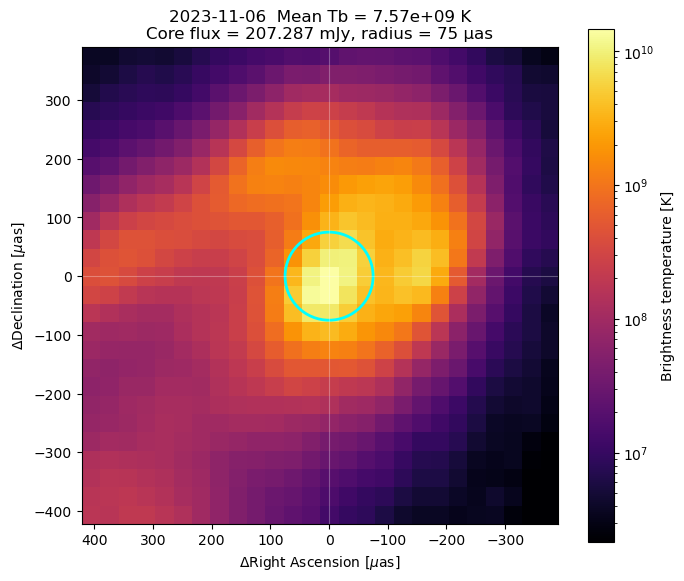

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-11-06/fits/1652+398Q.2023-11-06_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 51.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 3.03819526e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-11-06/core_flux/1652+398Q.2023-11-06_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-11-06/core_flux/core_brightness_temperature.png

観測日: 2023-11-25


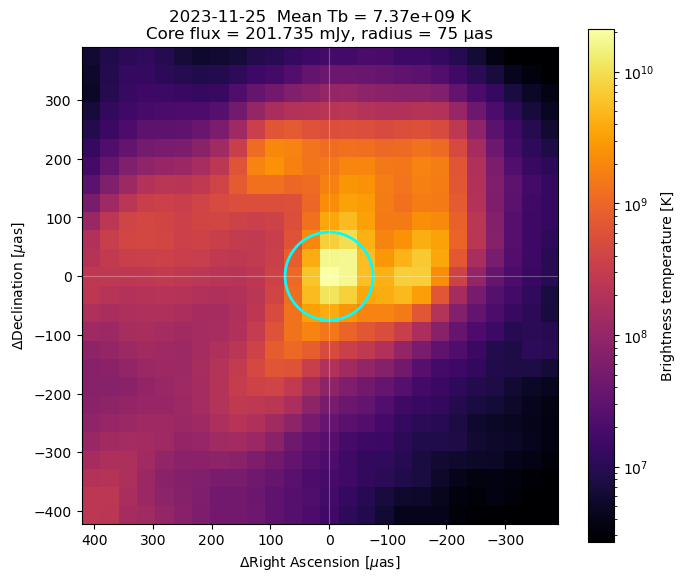

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-11-25/fits/1652+398Q.2023-11-25_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-11-25/core_flux/1652+398Q.2023-11-25_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-11-25/core_flux/core_brightness_temperature.png

観測日: 2023-12-12


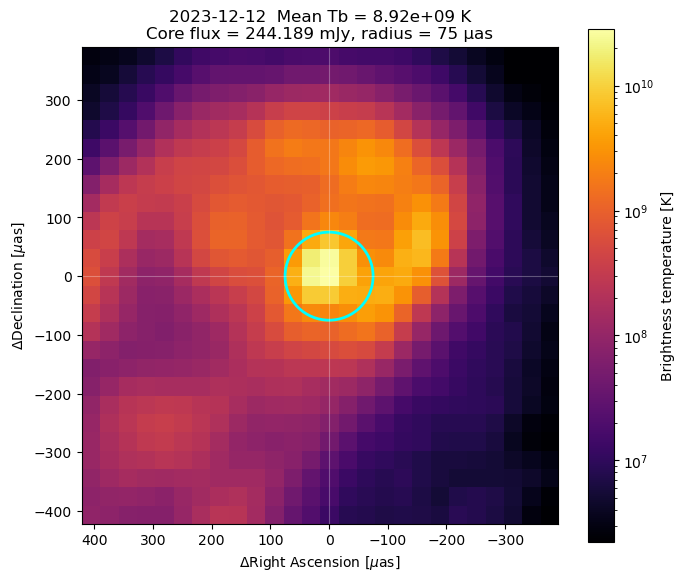

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-12-12/fits/1652+398Q.2023-12-12_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 2.17013918e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-12-12/core_flux/1652+398Q.2023-12-12_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2023-12-12/core_flux/core_brightness_temperature.png

観測日: 2024-02-11


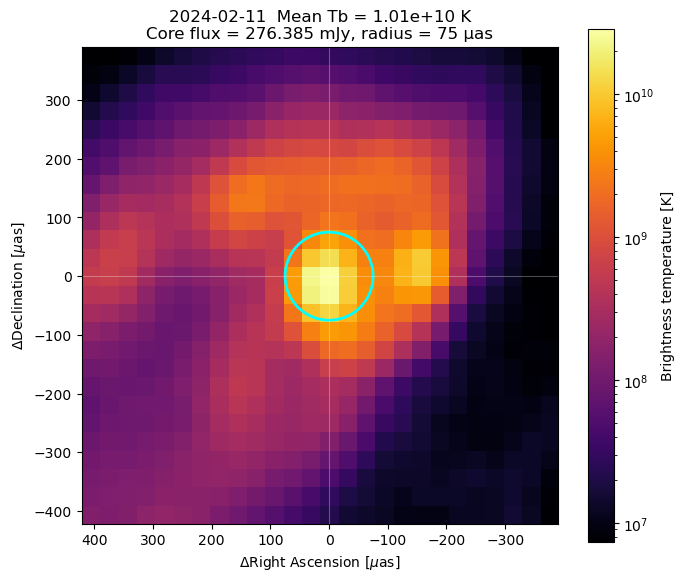

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-02-11/fits/1652+398Q.2024-02-11_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (49.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999999, 1.30208408e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-02-11/core_flux/1652+398Q.2024-02-11_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-02-11/core_flux/core_brightness_temperature.png

観測日: 2024-02-25


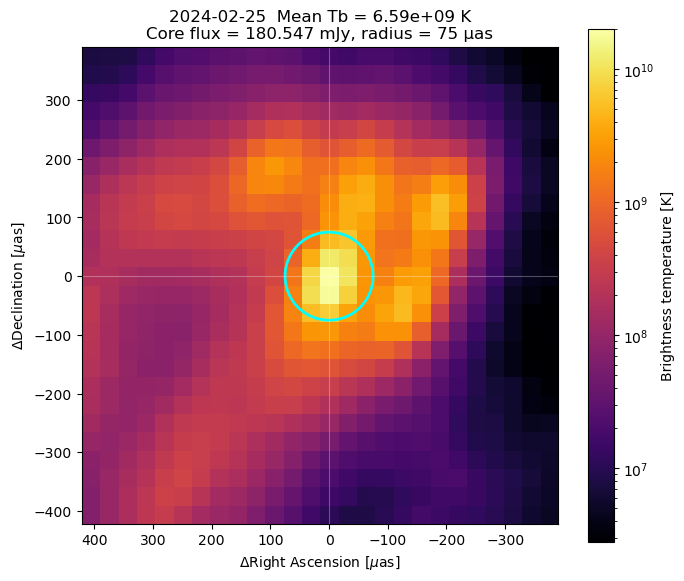

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-02-25/fits/1652+398Q.2024-02-25_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 51.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 3.03819526e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-02-25/core_flux/1652+398Q.2024-02-25_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-02-25/core_flux/core_brightness_temperature.png

観測日: 2024-03-22


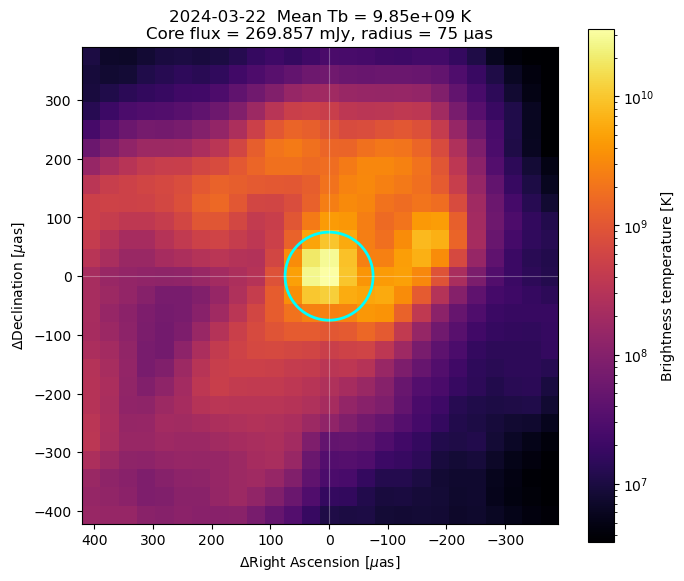

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-03-22/fits/1652+398Q.2024-03-22_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 1.30208403e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-03-22/core_flux/1652+398Q.2024-03-22_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-03-22/core_flux/core_brightness_temperature.png

観測日: 2024-05-25


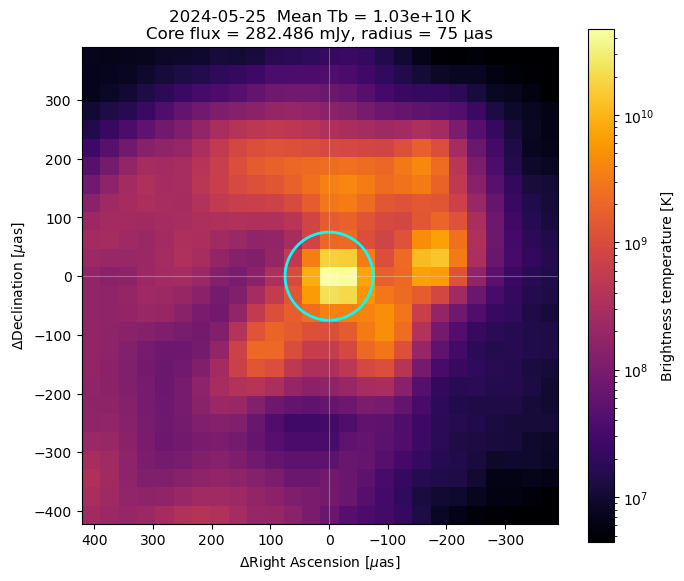

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-05-25/fits/1652+398Q.2024-05-25_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-05-25/core_flux/1652+398Q.2024-05-25_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-05-25/core_flux/core_brightness_temperature.png

観測日: 2024-06-08


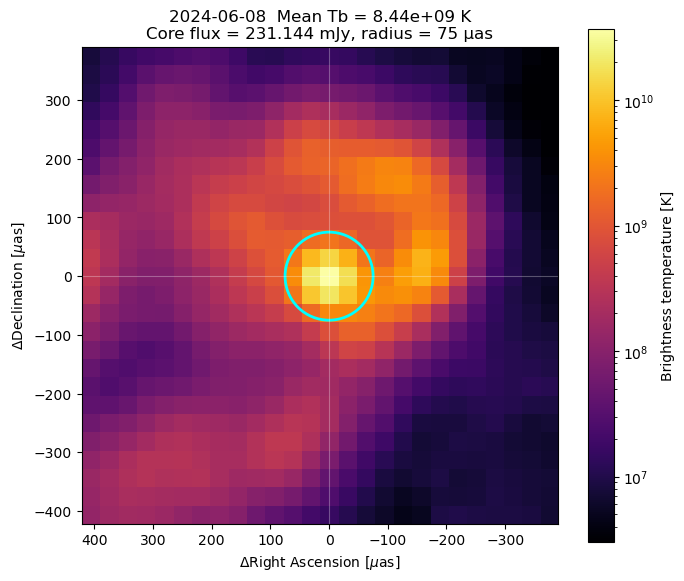

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-06-08/fits/1652+398Q.2024-06-08_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 2.17013918e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-06-08/core_flux/1652+398Q.2024-06-08_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-06-08/core_flux/core_brightness_temperature.png

観測日: 2024-07-03


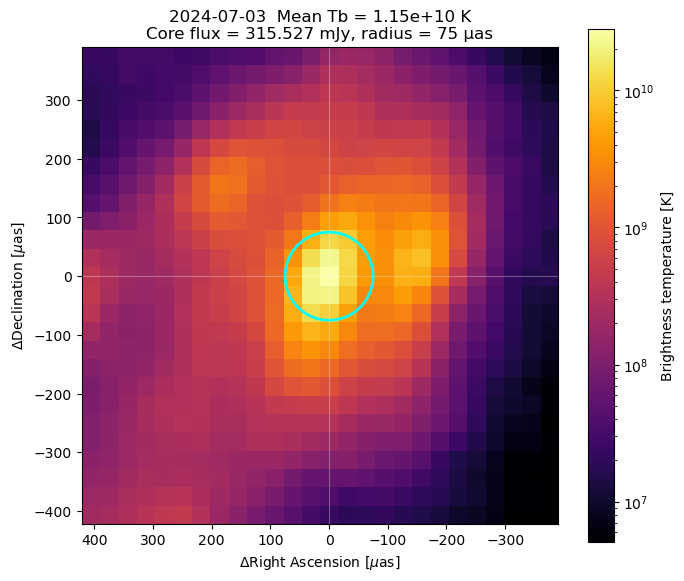

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-07-03/fits/1652+398Q.2024-07-03_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (55.000, 53.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999993, 4.77430642e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-07-03/core_flux/1652+398Q.2024-07-03_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-07-03/core_flux/core_brightness_temperature.png

観測日: 2024-08-03


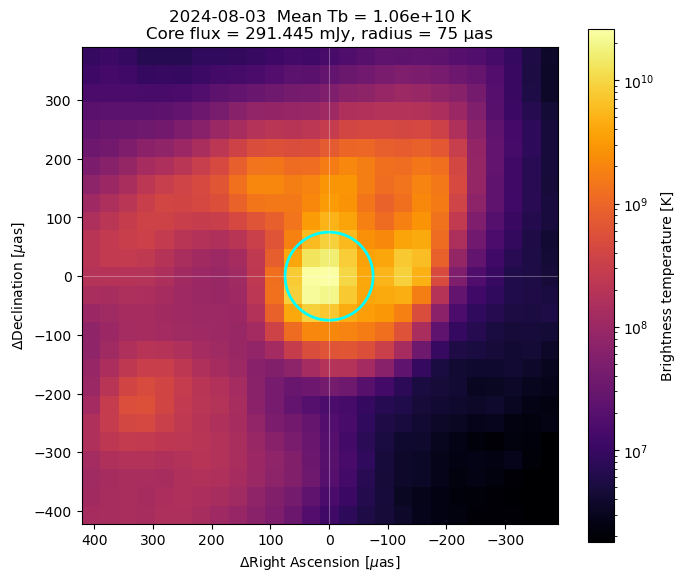

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-08-03/fits/1652+398Q.2024-08-03_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (50.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999998, 1.302084e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-08-03/core_flux/1652+398Q.2024-08-03_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-08-03/core_flux/core_brightness_temperature.png

観測日: 2024-08-31


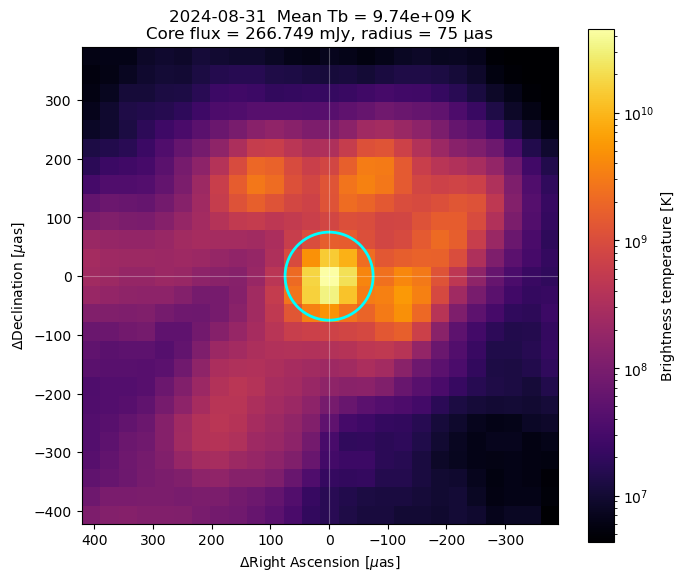

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-08-31/fits/1652+398Q.2024-08-31_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 51.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 3.03819526e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-08-31/core_flux/1652+398Q.2024-08-31_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-08-31/core_flux/core_brightness_temperature.png

観測日: 2024-09-13


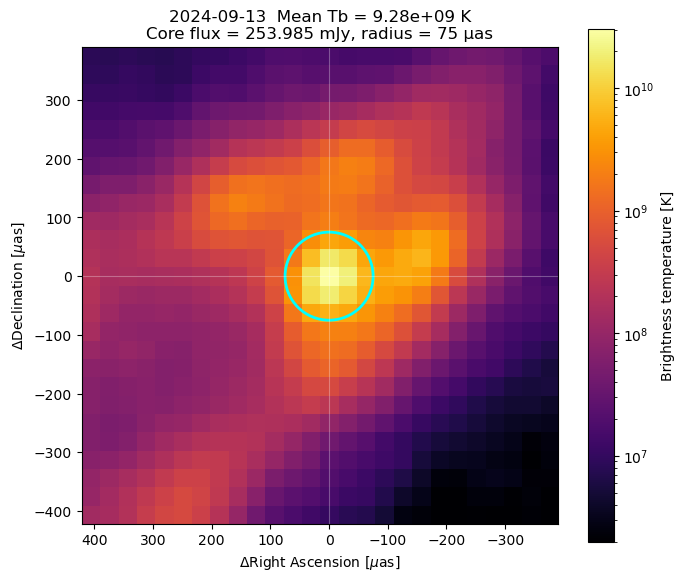

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-09-13/fits/1652+398Q.2024-09-13_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (53.000, 52.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999995, 3.90625037e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-09-13/core_flux/1652+398Q.2024-09-13_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-09-13/core_flux/core_brightness_temperature.png

観測日: 2024-10-14


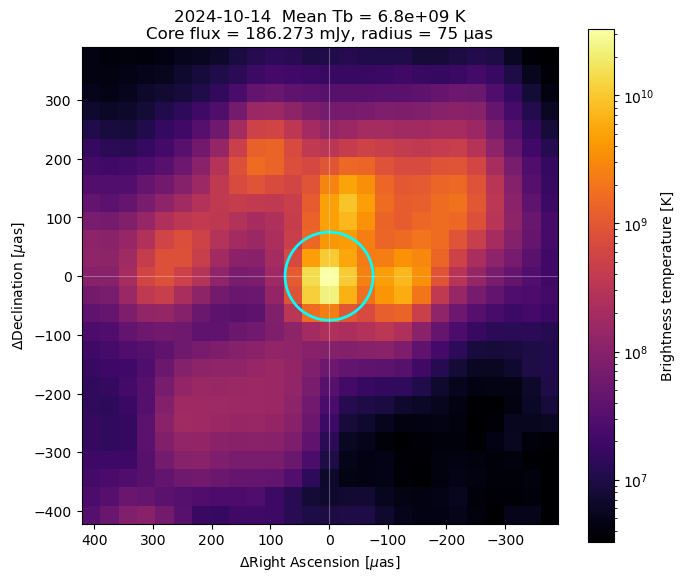

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-10-14/fits/1652+398Q.2024-10-14_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 51.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 3.03819526e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-10-14/core_flux/1652+398Q.2024-10-14_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-10-14/core_flux/core_brightness_temperature.png

観測日: 2024-11-21


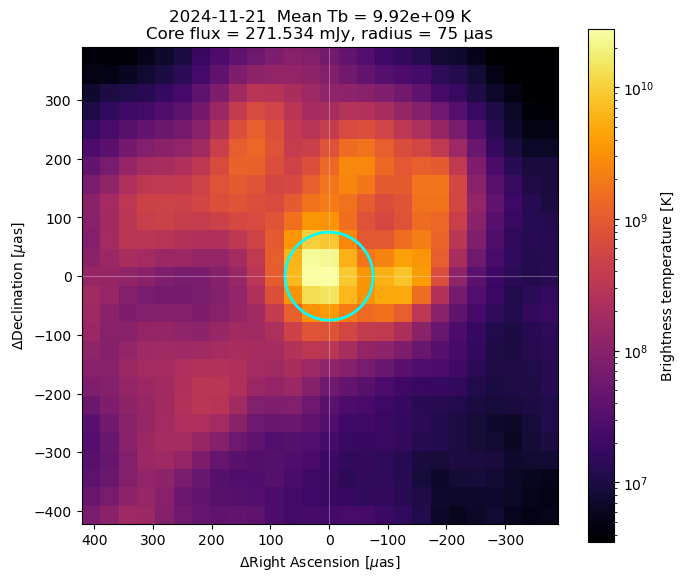

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-11-21/fits/1652+398Q.2024-11-21_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 2.17013918e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-11-21/core_flux/1652+398Q.2024-11-21_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-11-21/core_flux/core_brightness_temperature.png

観測日: 2024-12-15


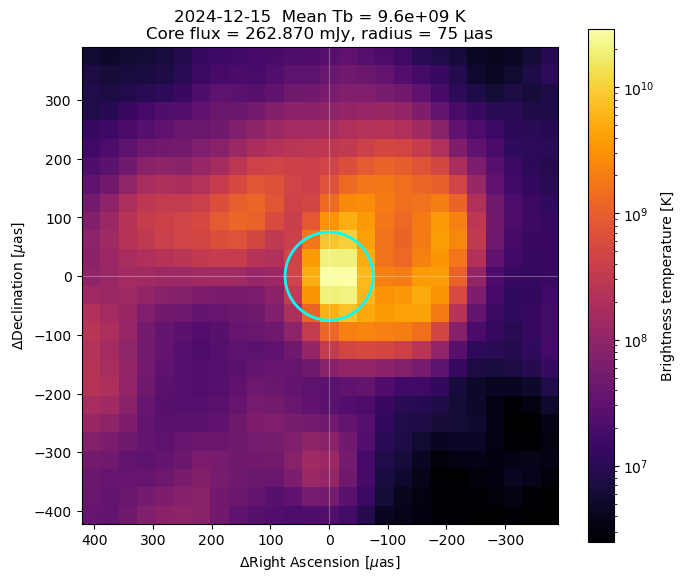

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-12-15/fits/1652+398Q.2024-12-15_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (50.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999998, 1.302084e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-12-15/core_flux/1652+398Q.2024-12-15_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2024-12-15/core_flux/core_brightness_temperature.png

観測日: 2025-02-16


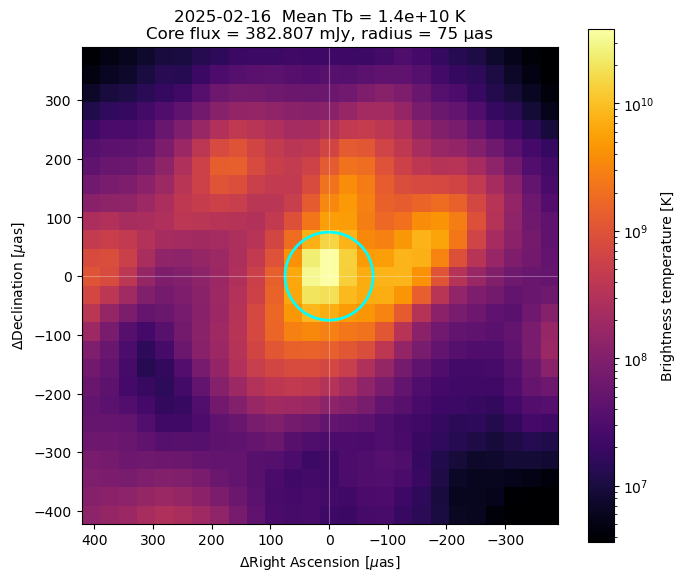

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-02-16/fits/1652+398Q.2025-02-16_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-02-16/core_flux/1652+398Q.2025-02-16_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-02-16/core_flux/core_brightness_temperature.png

観測日: 2025-03-09


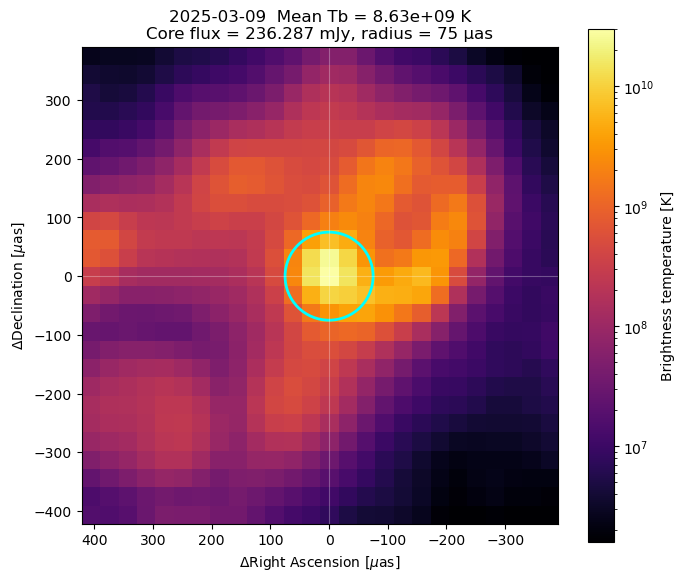

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-03-09/fits/1652+398Q.2025-03-09_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-03-09/core_flux/1652+398Q.2025-03-09_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-03-09/core_flux/core_brightness_temperature.png

観測日: 2025-03-23


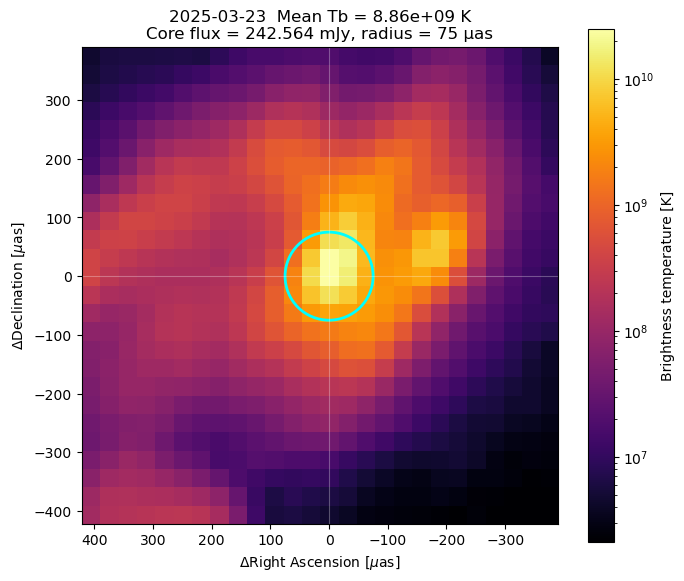

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-03-23/fits/1652+398Q.2025-03-23_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-03-23/core_flux/1652+398Q.2025-03-23_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-03-23/core_flux/core_brightness_temperature.png

観測日: 2025-04-14


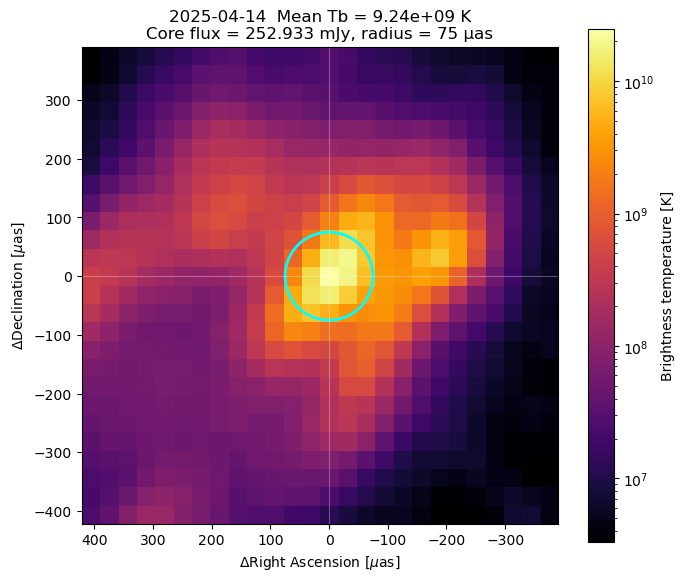

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-04-14/fits/1652+398Q.2025-04-14_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (53.000, 52.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999995, 3.90625037e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-04-14/core_flux/1652+398Q.2025-04-14_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-04-14/core_flux/core_brightness_temperature.png

観測日: 2025-05-11


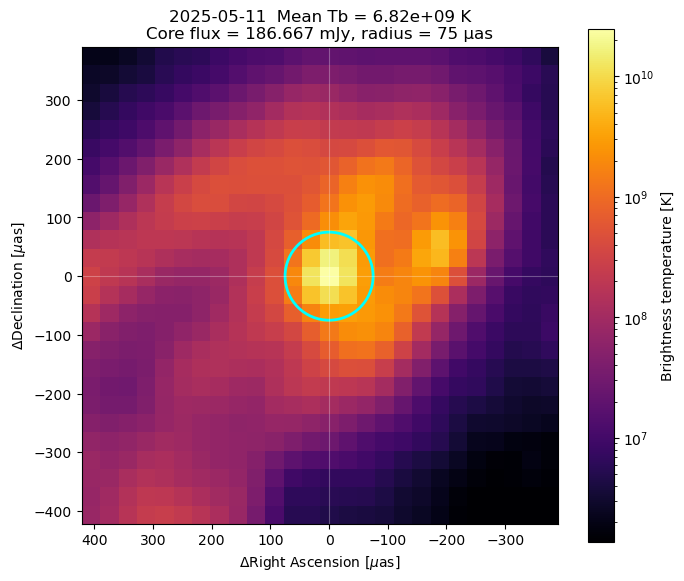

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/fits/1652+398Q.2025-05-11_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/core_flux/1652+398Q.2025-05-11_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-05-11/core_flux/core_brightness_temperature.png

観測日: 2025-07-17


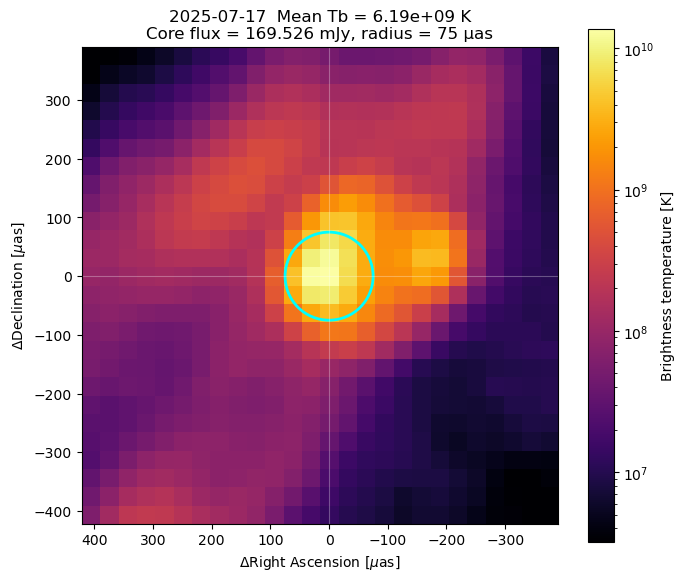

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-07-17/fits/1652+398Q.2025-07-17_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (49.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999999, 1.30208408e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-07-17/core_flux/1652+398Q.2025-07-17_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-07-17/core_flux/core_brightness_temperature.png

観測日: 2025-08-04


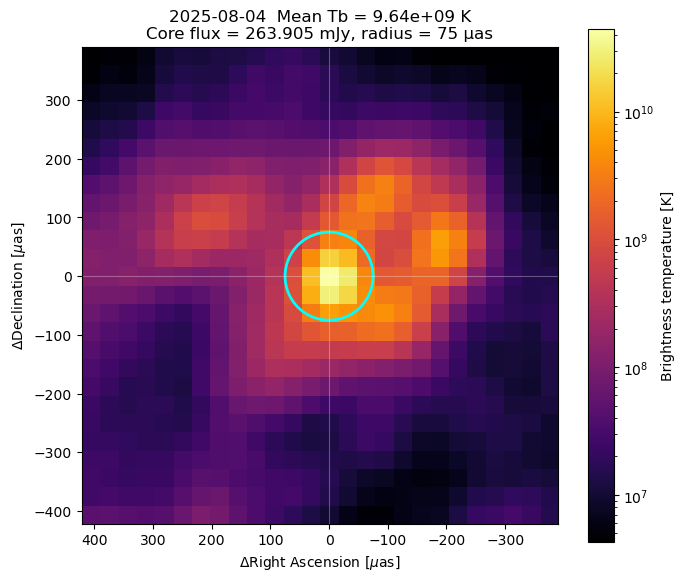

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-08-04/fits/1652+398Q.2025-08-04_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (51.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999997, 2.17013866e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-08-04/core_flux/1652+398Q.2025-08-04_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-08-04/core_flux/core_brightness_temperature.png

観測日: 2025-08-28


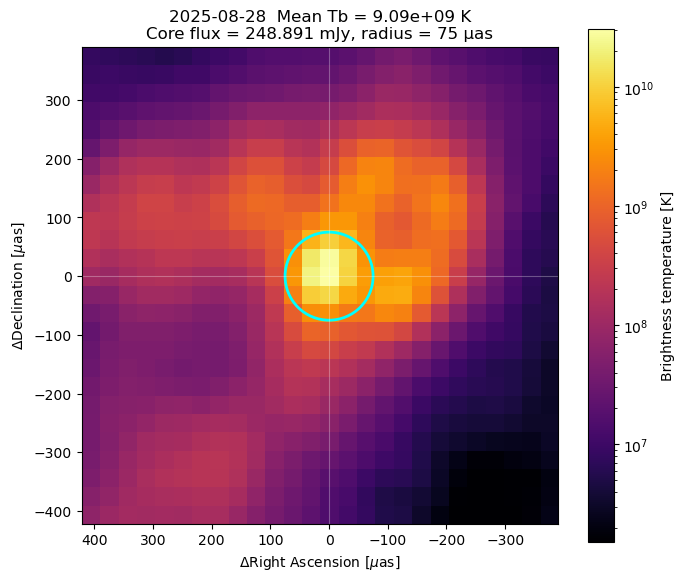

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-08-28/fits/1652+398Q.2025-08-28_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (52.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999996, 1.30208407e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-08-28/core_flux/1652+398Q.2025-08-28_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-08-28/core_flux/core_brightness_temperature.png

観測日: 2025-09-18


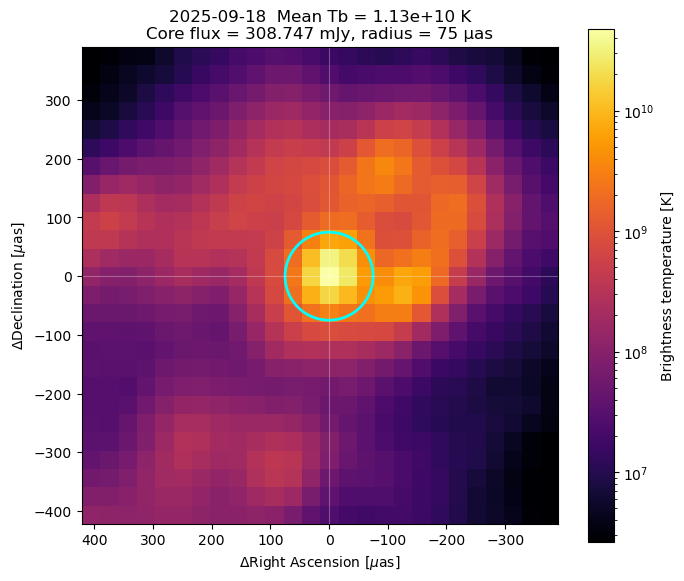

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-09-18/fits/1652+398Q.2025-09-18_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (50.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999998, 1.302084e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-09-18/core_flux/1652+398Q.2025-09-18_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-09-18/core_flux/core_brightness_temperature.png

観測日: 2025-11-24


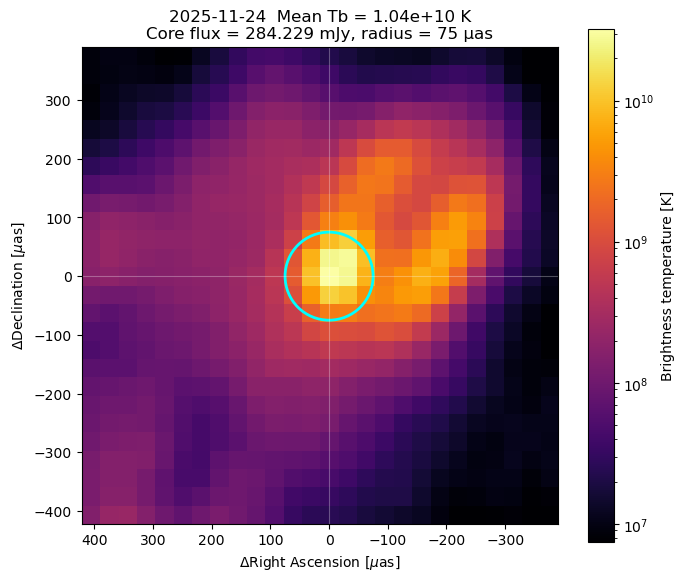

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-11-24/fits/1652+398Q.2025-11-24_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (50.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999998, 2.17013913e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-11-24/core_flux/1652+398Q.2025-11-24_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-11-24/core_flux/core_brightness_temperature.png

観測日: 2025-12-27


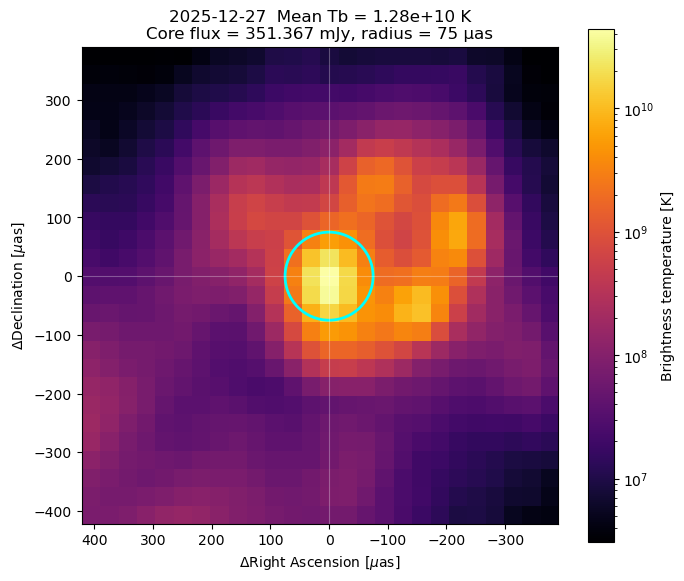

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-12-27/fits/1652+398Q.2025-12-27_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (49.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999999, 2.17013976e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-12-27/core_flux/1652+398Q.2025-12-27_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2025-12-27/core_flux/core_brightness_temperature.png

観測日: 2026-03-08


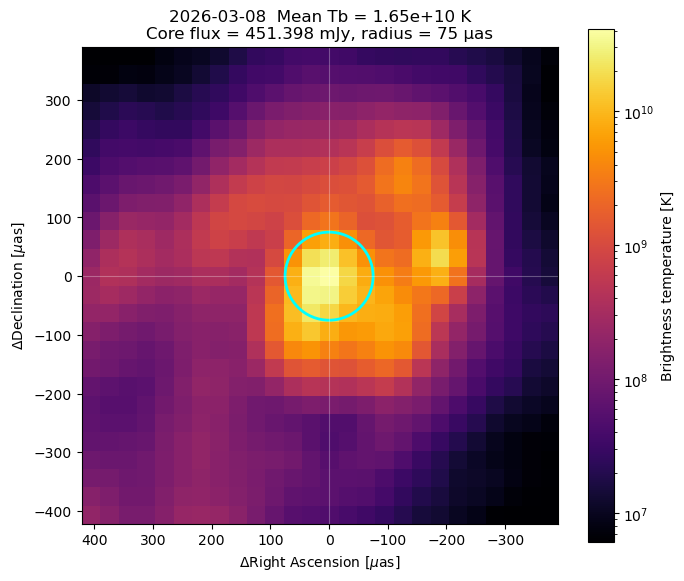

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-03-08/fits/1652+398Q.2026-03-08_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (49.000, 50.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999999, 2.17013976e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-03-08/core_flux/1652+398Q.2026-03-08_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-03-08/core_flux/core_brightness_temperature.png

観測日: 2026-05-01


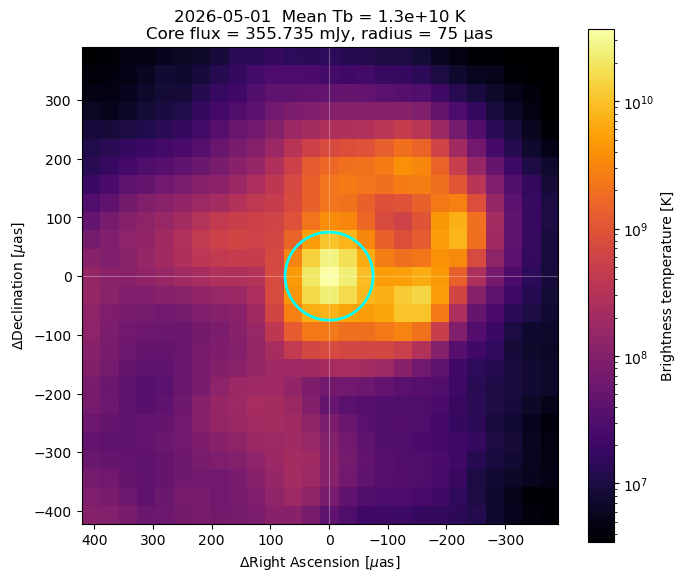

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-05-01/fits/1652+398Q.2026-05-01_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (48.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (360., 1.30208389e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-05-01/core_flux/1652+398Q.2026-05-01_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-05-01/core_flux/core_brightness_temperature.png

観測日: 2026-05-15


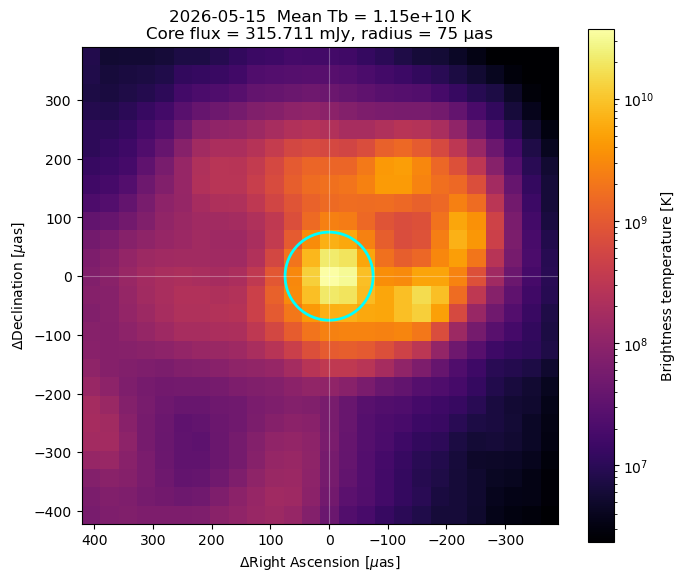

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-05-15/fits/1652+398Q.2026-05-15_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (48.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (360., 1.30208389e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-05-15/core_flux/1652+398Q.2026-05-15_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-05-15/core_flux/core_brightness_temperature.png

観測日: 2026-06-19


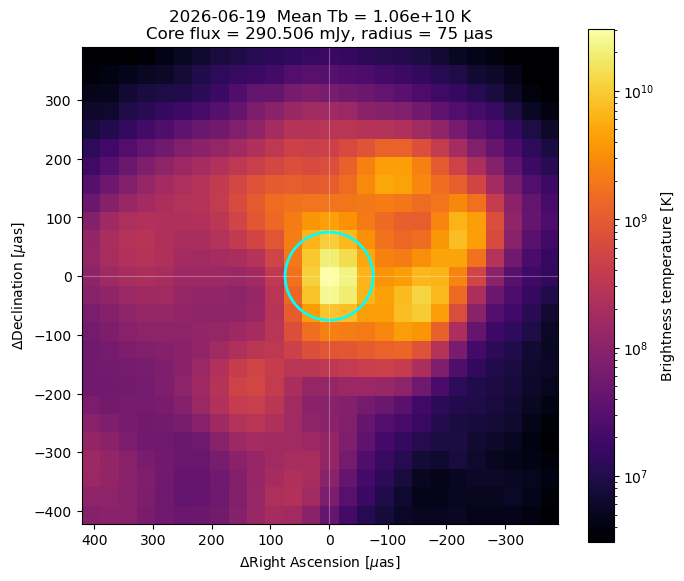

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-06-19/fits/1652+398Q.2026-06-19_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (48.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (360., 1.30208389e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-06-19/core_flux/1652+398Q.2026-06-19_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-06-19/core_flux/core_brightness_temperature.png

観測日: 2026-07-05


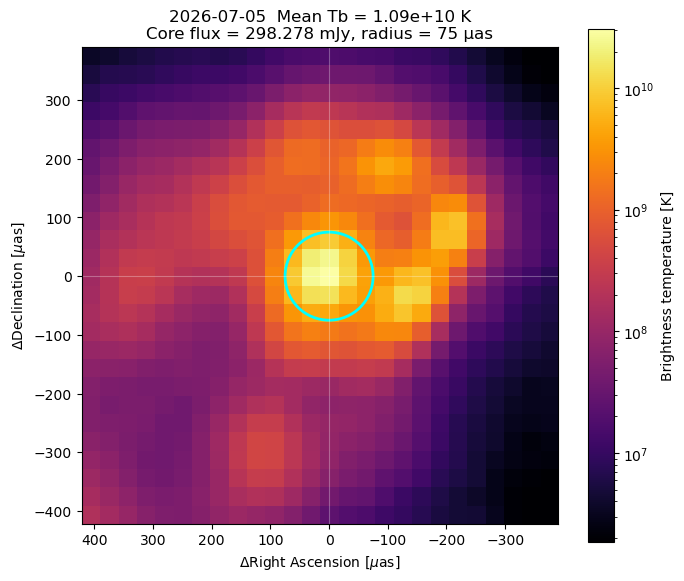

元画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-07-05/fits/1652+398Q.2026-07-05_mimg.fits | (96, 96) | jy_per_pixel
周波数: 43 GHz
コア中心: (x, y) = (49.000, 49.000), 使用画素数: 21
画素サイズ: 31.2500 × 31.2500 μas
コアの天球座標: <SkyCoord (ICRS): (ra, dec) in deg
    (359.99999999, 1.30208408e-08)>
切り出しFITS: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-07-05/core_flux/1652+398Q.2026-07-05_mimg_core_cutout_Tb.fits
確認画像: /Users/reiya/Desktop/imaging/results_fov3000/Mrk501_2026-07-05/core_flux/core_brightness_temperature.png

観測日       平均輝度温度 [K]   最大輝度温度 [K]   積分フラックス [mJy]
2023-05-21   8.7483e+09 ± 3.59e+09   2.7151e+10 ± 8.61e+09   239.55 ± 98.2
2023-06-01   1.4123e+10 ± 5.04e+09   5.297e+10 ± 1.51e+10   386.74 ± 138
2023-07-01   9.1845e+09 ± 5.09e+09   3.7936e+10 ± 1.36e+10   251.5 ± 139
2023-07-15   9.9353e+09 ± 5.4e+09   3.5067e+10 ± 1.17e+10   272.06 ± 148
2023-07-24   9.7925e+09 ± 4.68e+09   3.4904e+10 ± 1.21e+10   268.15 ± 128
2023-10-13   8.9882e+09 ± 4.56e+09   3.9695e+10

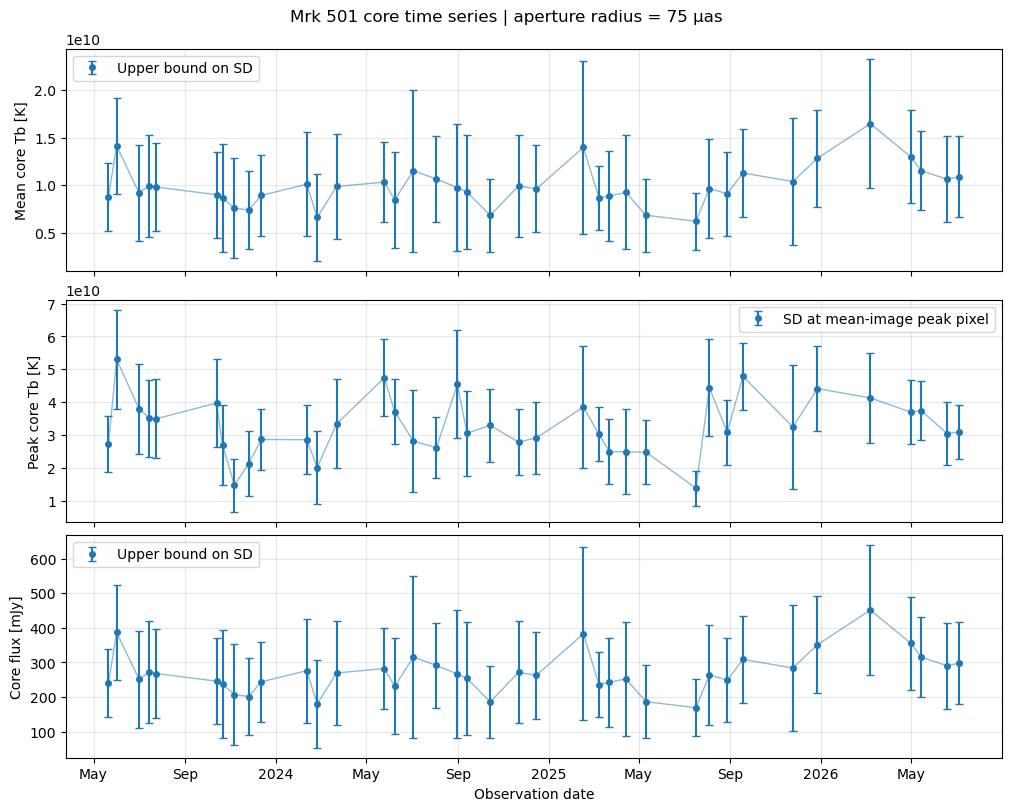

In [13]:
epoch_files = []
for fits_path in sorted(base_results_dir.glob("Mrk501_*/fits/*_mimg.fits")):
    date_string = fits_path.parent.parent.name.removeprefix("Mrk501_")
    try:
        obs_date = datetime.strptime(date_string, "%Y-%m-%d")
    except ValueError:
        continue
    if target_dates is None or date_string in target_dates:
        epoch_files.append((obs_date, fits_path))

epoch_files.sort(key=lambda item: item[0])
if not epoch_files:
    raise FileNotFoundError(
        f"対象FITSが見つかりません: {base_results_dir}/Mrk501_*/fits/*_mimg.fits"
    )

print(f"処理するエポック: {len(epoch_files)} 件")
results = []
for obs_date, fits_path in epoch_files:
    print(f"\n観測日: {obs_date:%Y-%m-%d}")
    results.append(analyze_epoch(obs_date, fits_path))

metrics = [
    ("mean_tb_K", "Mean core Tb [K]", 1.0),
    ("peak_tb_K", "Peak core Tb [K]", 1.0),
    ("flux_jy", "Core flux [mJy]", 1000.0),
]
notes = (
    ["Posterior SD"] * 3
    if ERROR_MODE == "posterior_samples"
    else ["Upper bound on SD", "SD at mean-image peak pixel", "Upper bound on SD"]
)

print("\n観測日       平均輝度温度 [K]   最大輝度温度 [K]   積分フラックス [mJy]")
for item in results:
    measurements = []
    for key, _, scale in metrics:
        value = item[key] * scale
        error = item[f"{key}_err"] * scale
        text = (
            f"{value:.5g} ± {error:.3g}"
            if np.isfinite(error)
            else f"{value:.5g} (誤差未推定)"
        )
        measurements.append(text)
    print(f'{item["date"]:%Y-%m-%d}   ' + "   ".join(measurements))

fig, axes = plt.subplots(
    3, 1, figsize=(10, 8), sharex=True, constrained_layout=True
)
dates = np.array([item["date"] for item in results])

for ax, (key, ylabel, scale), note in zip(axes, metrics, notes):
    values = np.array([item[key] for item in results]) * scale
    errors = np.array([item[f"{key}_err"] for item in results]) * scale
    valid = np.isfinite(errors)

    ax.plot(dates, values, color="C0", linewidth=1, alpha=0.5)
    if valid.any():
        ax.errorbar(
            dates[valid], values[valid], yerr=errors[valid],
            fmt="o", color="C0", markersize=4, capsize=3, label=note,
        )
    if (~valid).any():
        ax.plot(
            dates[~valid], values[~valid], "o", color="C0",
            markersize=4, markerfacecolor="none", label="No uncertainty file",
        )
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

locator = mdates.AutoDateLocator()
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[-1].set_xlabel("Observation date")
fig.suptitle(f"Mrk 501 core time series | aperture radius = {core_radius_uas:g} μas")

summary_dir = base_results_dir / "core_brightness_temperature_summary"
summary_dir.mkdir(parents=True, exist_ok=True)
summary_png = summary_dir / "core_time_series_with_errorbars.png"
fig.savefig(summary_png, dpi=200)
print(f"\n時系列グラフ: {summary_png}")
plt.show()
plt.close(fig)